In [5]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Calibri", "Helvetica"],
    "mathtext.fontset": "dejavusans",
    "font.size": 20,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
    "figure.titlesize": 20,
})

PALETTE = {
    "lsnr": "#ff7f0e",
    "nrms": "#2ca02c",
    "naml": "#9467bd",
    "lstur": "#1f77b4",
    "news": "#d62728",
}

MODEL_STYLES = {
    "lsnr": {"marker": "o", "color": PALETTE["lsnr"], "label": "LSNR"},
    "nrms": {"marker": "s", "color": PALETTE["nrms"], "label": "NRMS"},
    "naml": {"marker": "^", "color": PALETTE["naml"], "label": "NAML"},
    "lstur": {"marker": "X", "color": PALETTE["lstur"], "label": "LSTUR"},
}

def plot_history_curves(payload: dict) -> None:
    order = payload["order"]
    labels = payload.get("labels", order)
    x_positions = np.arange(len(order))

    plt.figure(figsize=(8, 8))
    for model_key, style in MODEL_STYLES.items():
        series = payload["scores"].get(model_key, {})
        values = [series.get(step, np.nan) for step in order]
        plt.plot(
            x_positions,
            values,
            marker=style["marker"],
            linewidth=2,
            color=style["color"],
            label=style["label"],
        )

    if payload.get("title"):
        plt.title(payload["title"])

    plt.xlabel("History length threshold")
    plt.ylabel("nDCG@10")
    plt.xticks(x_positions, labels)
    plt.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
    plt.legend()
    plt.show()


def plot_tradeoff(
    points: list[dict],
    *,
    x_key: str,
    x_label: str,
    color: str,
    title: str | None = None,
    log_x: bool = False,
    xticks: list[float] | None = None,
    annotate: bool = False,
    vertical_lines: bool = True,
) -> None:
    ordered_points = sorted(points, key=lambda item: item[x_key])
    x_vals = np.array([point[x_key] for point in ordered_points])
    y_vals = np.array([point["ndcg10"] for point in ordered_points])
    labels = [point["label"] for point in ordered_points]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(
        x_vals,
        y_vals,
        marker="o",
        markersize=8,
        markerfacecolor=color,
        markeredgecolor=color,
        linewidth=2,
        color=color,
    )

    if log_x:
        ax.set_xscale("log")

    if xticks:
        ax.set_xticks(xticks)
        ax.set_xticklabels([str(int(tick)) for tick in xticks])

    if vertical_lines:
        ymin, ymax = ax.get_ylim()
        ax.vlines(x_vals, ymin=ymin, ymax=ymax, colors=color, linestyles="--", alpha=0.25, linewidth=1)
        ax.set_ylim(ymin, ymax)

    if annotate:
        for x_val, y_val, lbl in zip(x_vals, y_vals, labels):
            ax.annotate(lbl, (x_val, y_val), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=12)

    ax.set_xlabel(x_label)
    ax.set_ylabel("nDCG@10")
    if title:
        ax.set_title(title)
    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
    fig.tight_layout()
    plt.show()



## History-length sensitivity

Comparing validation nDCG@10 across history-length thresholds highlights how sparse models behave for short-history users. 
Each plot shows the same set of models evaluated with progressively stricter limits on user interaction history.


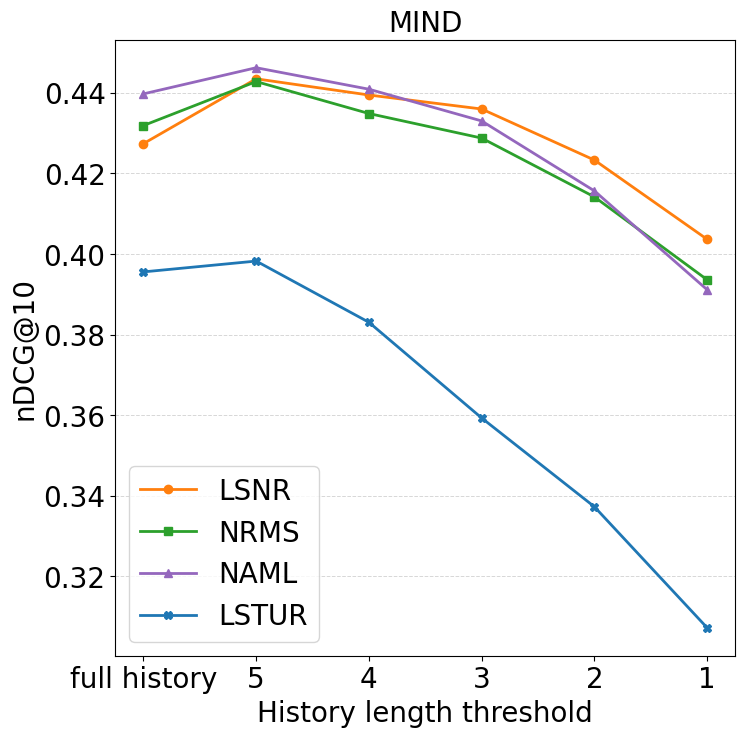

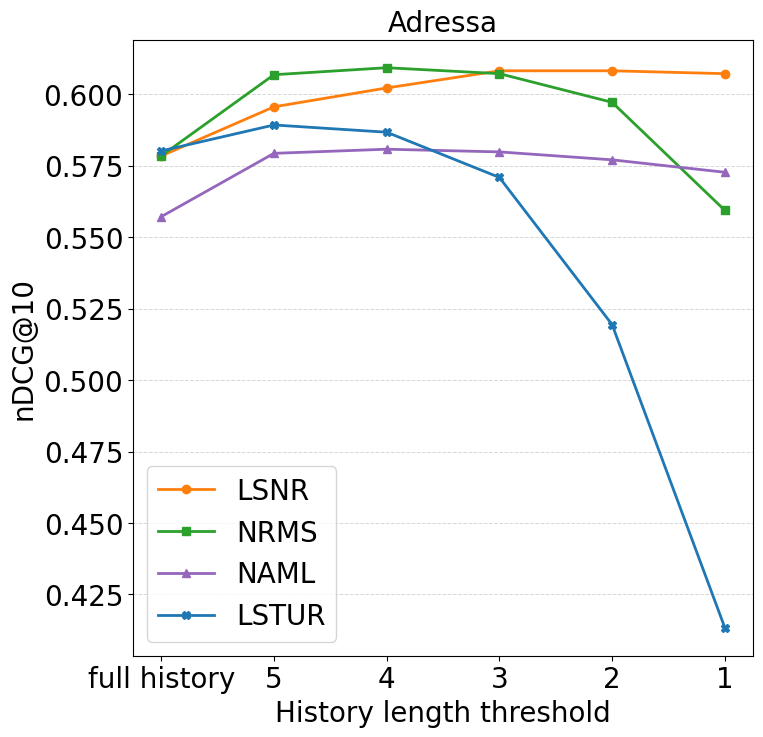

In [8]:
history_datasets = [
    {
        "title": "MIND",
        "order": ["full history", "5", "4", "3", "2", "1"],
        "scores": {
            "lsnr": {"full history": 0.427374, "5": 0.443453, "4": 0.439434, "3": 0.435962, "2": 0.423302, "1": 0.403646},
            "nrms": {"full history": 0.431865, "5": 0.442771, "4": 0.434842, "3": 0.428749, "2": 0.414161, "1": 0.393596},
            "naml": {"full history": 0.439718, "5": 0.446205, "4": 0.440875, "3": 0.432998, "2": 0.415650, "1": 0.391140},
            "lstur": {"full history": 0.395552, "5": 0.398235, "4": 0.383049, "3": 0.359308, "2": 0.337287, "1": 0.307271},
        },
    },
    {
        "title": "Adressa",
        "order": ["full history", "5", "4", "3", "2", "1"],
        "scores": {
            "lsnr": {"full history": 0.5784, "5": 0.5955961204707939, "4": 0.6022, "3": 0.6082, "2": 0.6082, "1": 0.6072},
            "nrms": {"full history": 0.5784330984932258, "5": 0.6068327313237942, "4": 0.6092780796812097, "3": 0.6072025139273423, "2": 0.5971707052146847, "1": 0.559379671917213},
            "naml": {"full history": 0.5571664917480863, "5": 0.5793268110282539, "4": 0.5807726412237828, "3": 0.5798299418069595, "2": 0.5770522146771249, "1": 0.5727068322169674},
            "lstur": {"full history": 0.580174415966005, "5": 0.5892490351347668, "4": 0.5867180288677596, "3": 0.5708982778070215, "2": 0.519408091950595, "1": 0.413371047732992},
        },
    },
]

for payload in history_datasets:
    plot_history_curves(payload)



## Efficiency vs. performance trade-off

Scatter plots pair validation nDCG@10 with the average number of active dimensions. 
Moving left corresponds to stronger sparsity; use these plots to spot checkpoints that balance accuracy with minimal representations.


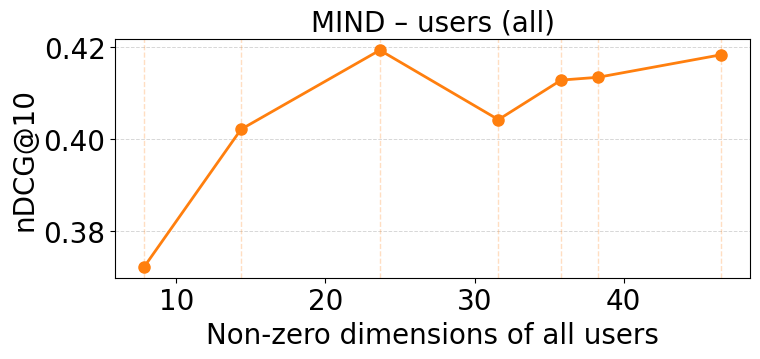

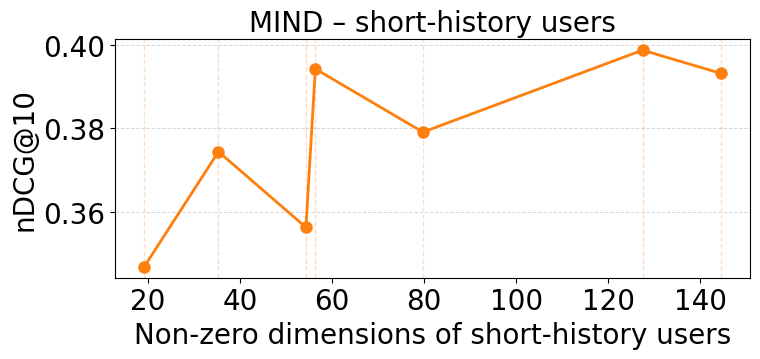

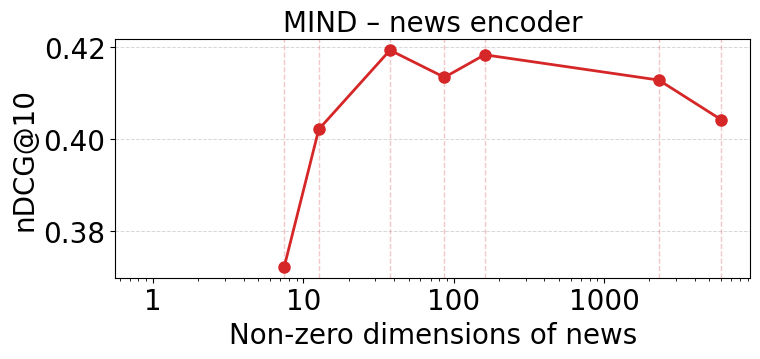

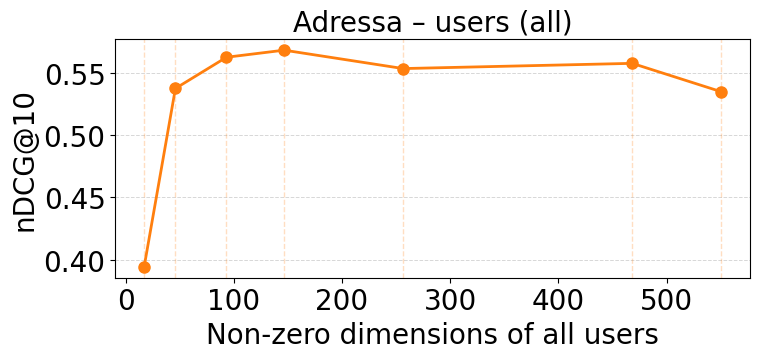

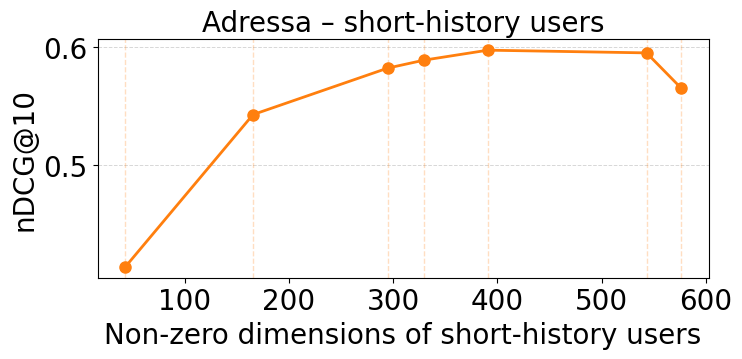

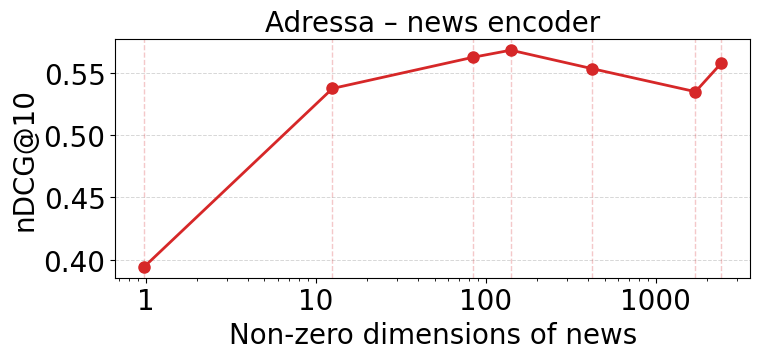

In [7]:
TRADEOFF_STYLES = {
    "user_all": {
        "x_key": "user_nonzero",
        "x_label": "Non-zero dimensions of all users",
        "color": PALETTE["lsnr"],
        "title_suffix": "users (all)",
    },
    "user_short": {
        "x_key": "user_nonzero",
        "x_label": "Non-zero dimensions of short-history users",
        "color": PALETTE["lsnr"],
        "title_suffix": "short-history users",
    },
    "news": {
        "x_key": "news_nonzero",
        "x_label": "Non-zero dimensions of news",
        "color": PALETTE["news"],
        "title_suffix": "news encoder",
        "log_x": True,
        "xticks": [1, 10, 100, 1000, 10000],
    },
}

tradeoff_data = {
    "MIND": {
        "user_all": [
            {"label": "baseline", "user_nonzero": 38.27, "ndcg10": 0.4134},
            {"label": "extreme_regularization", "user_nonzero": 14.34, "ndcg10": 0.4021},
            {"label": "high_regularization", "user_nonzero": 46.54, "ndcg10": 0.4183},
            {"label": "low_regularization", "user_nonzero": 35.81, "ndcg10": 0.4128},
            {"label": "no_regularization", "user_nonzero": 31.60, "ndcg10": 0.4042},
            {"label": "very_extreme_regularization", "user_nonzero": 7.84, "ndcg10": 0.3722},
            {"label": "very_high_regularization", "user_nonzero": 23.65, "ndcg10": 0.4193},
        ],
        "user_short": [
            {"label": "baseline", "user_nonzero": 127.46, "ndcg10": 0.3988},
            {"label": "extreme_regularization", "user_nonzero": 35.31, "ndcg10": 0.3744},
            {"label": "high_regularization", "user_nonzero": 144.54, "ndcg10": 0.3932},
            {"label": "low_regularization", "user_nonzero": 79.74, "ndcg10": 0.3791},
            {"label": "no_regularization", "user_nonzero": 54.31, "ndcg10": 0.3562},
            {"label": "very_extreme_regularization", "user_nonzero": 19.15, "ndcg10": 0.3467},
            {"label": "very_high_regularization", "user_nonzero": 56.36, "ndcg10": 0.3943},
        ],
        "news": [
            {"label": "baseline", "news_nonzero": 86.66, "ndcg10": 0.4134},
            {"label": "extreme_regularization", "news_nonzero": 12.65, "ndcg10": 0.4021},
            {"label": "high_regularization", "news_nonzero": 160.36, "ndcg10": 0.4183},
            {"label": "low_regularization", "news_nonzero": 2309.91, "ndcg10": 0.4128},
            {"label": "no_regularization", "news_nonzero": 5997.73, "ndcg10": 0.4042},
            {"label": "very_extreme_regularization", "news_nonzero": 7.45, "ndcg10": 0.3722},
            {"label": "very_high_regularization", "news_nonzero": 37.65, "ndcg10": 0.4193},
        ],
    },
    "Adressa": {
        "user_all": [
            {"label": "baseline", "user_nonzero": 256.56, "ndcg10": 0.5536},
            {"label": "extreme_regularization", "user_nonzero": 46.05, "ndcg10": 0.5376},
            {"label": "high_regularization", "user_nonzero": 146.53, "ndcg10": 0.5684},
            {"label": "low_regularization", "user_nonzero": 550.48, "ndcg10": 0.5350},
            {"label": "no_regularization", "user_nonzero": 468.27, "ndcg10": 0.5578},
            {"label": "very_extreme_regularization", "user_nonzero": 17.13, "ndcg10": 0.3941},
            {"label": "very_high_regularization", "user_nonzero": 93.23, "ndcg10": 0.5627},
        ],
        "user_short": [
            {"label": "baseline", "user_nonzero": 329.83, "ndcg10": 0.5888},
            {"label": "extreme_regularization", "user_nonzero": 165.42, "ndcg10": 0.5427},
            {"label": "high_regularization", "user_nonzero": 390.88, "ndcg10": 0.5972},
            {"label": "low_regularization", "user_nonzero": 576.08, "ndcg10": 0.5654},
            {"label": "no_regularization", "user_nonzero": 543.18, "ndcg10": 0.5949},
            {"label": "very_extreme_regularization", "user_nonzero": 42.82, "ndcg10": 0.4139},
            {"label": "very_high_regularization", "user_nonzero": 294.60, "ndcg10": 0.5820},
        ],
        "news": [
            {"label": "baseline", "news_nonzero": 420.43, "ndcg10": 0.5536},
            {"label": "extreme_regularization", "news_nonzero": 12.56, "ndcg10": 0.5376},
            {"label": "high_regularization", "news_nonzero": 140.62, "ndcg10": 0.5684},
            {"label": "low_regularization", "news_nonzero": 1712.66, "ndcg10": 0.5350},
            {"label": "no_regularization", "news_nonzero": 2425.49, "ndcg10": 0.5578},
            {"label": "very_extreme_regularization", "news_nonzero": 0.98, "ndcg10": 0.3941},
            {"label": "very_high_regularization", "news_nonzero": 84.41, "ndcg10": 0.5627},
        ],
    },
}

for dataset_name, series_dict in tradeoff_data.items():
    for key, points in series_dict.items():
        style = TRADEOFF_STYLES[key]
        plot_tradeoff(
            points,
            x_key=style["x_key"],
            x_label=style["x_label"],
            color=style["color"],
            title=f"{dataset_name} – {style['title_suffix']}",
            log_x=style.get("log_x", False),
            xticks=style.get("xticks"),
        )

